# Fuel Consumption Prediction (MPG) with Neural Network

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

df = pd.read_csv("mpg.csv")
df.head()

Using device: mps


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


## 1. Load Data — Observations & Missing Values

In [2]:
print(f"Number of observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")
print("\nData types:")
print(df.dtypes)

print("\nMissing (NaN) values per column:")
print(df.isna().sum())

print("\nAdditionally checking for hidden placeholders like '?':")
for col in df.columns:
    if df[col].dtype == object:
        print(col, "-> unique values (sample):", df[col].unique()[:10])

Number of observations: 398
Number of features: 9

Data types:
mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
model_year        int64
origin            int64
name             object
dtype: object

Missing (NaN) values per column:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Additionally checking for hidden placeholders like '?':
horsepower -> unique values (sample): ['130' '165' '150' '140' '198' '220' '215' '225' '190' '170']
name -> unique values (sample): ['chevrolet chevelle malibu' 'buick skylark 320' 'plymouth satellite'
 'amc rebel sst' 'ford torino' 'ford galaxie 500' 'chevrolet impala'
 'plymouth fury iii' 'pontiac catalina' 'amc ambassador dpl']


## 2. Examine the 'horsepower' Feature & Apply Preprocessing

This section takes a closer look at `horsepower` specifically, since it is 
the feature most likely to require cleaning in this dataset.

In [3]:
print("Current dtype of 'horsepower':", df['horsepower'].dtype)
print("\nSample raw values:")
print(df['horsepower'].unique()[:15])

# In the classic Auto-MPG dataset, horsepower is stored as a string ('object')
# because missing values are encoded as '?' instead of NaN. isna() therefore
# misses them above — we need to check explicitly.
non_numeric_mask = pd.to_numeric(df['horsepower'], errors='coerce').isna() & df['horsepower'].notna()
print(f"\nRows with non-numeric placeholder values: {non_numeric_mask.sum()}")
print(df.loc[non_numeric_mask, ['name', 'horsepower']])

Current dtype of 'horsepower': object

Sample raw values:
['130' '165' '150' '140' '198' '220' '215' '225' '190' '170' '160' '95'
 '97' '85' '88']

Rows with non-numeric placeholder values: 6
                     name horsepower
32             ford pinto          ?
126         ford maverick          ?
330  renault lecar deluxe          ?
336    ford mustang cobra          ?
354           renault 18i          ?
374        amc concord dl          ?


In [4]:
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

print(f"'horsepower' dtype after conversion: {df['horsepower'].dtype}")
print(f"Missing values after conversion: {df['horsepower'].isna().sum()}")

'horsepower' dtype after conversion: float64
Missing values after conversion: 6


count    392.000000
mean     104.469388
std       38.491160
min       46.000000
25%       75.000000
50%       93.500000
75%      126.000000
max      230.000000
Name: horsepower, dtype: float64


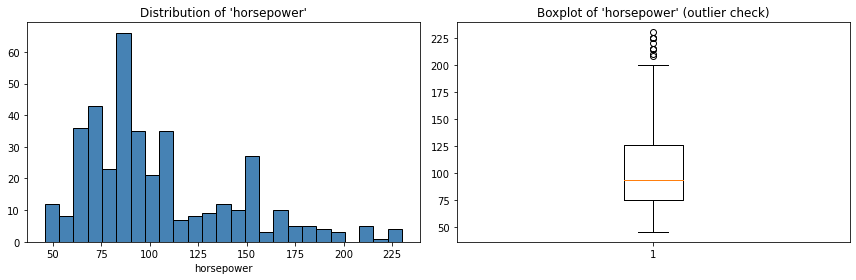

Skewness: 1.087


In [5]:
print(df['horsepower'].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['horsepower'].dropna(), bins=25, color='steelblue', edgecolor='black')
axes[0].set_title("Distribution of 'horsepower'")
axes[0].set_xlabel("horsepower")

axes[1].boxplot(df['horsepower'].dropna(), vert=True)
axes[1].set_title("Boxplot of 'horsepower' (outlier check)")
plt.tight_layout()
plt.show()

# Check skewness to decide between mean vs. median imputation
print(f"Skewness: {df['horsepower'].skew():.3f}")

**Preprocessing decision:** The distribution of `horsepower` is right-skewed 
(long tail toward high-horsepower vehicles) and contains a few high-value 
outliers, as seen in the boxplot. Because the mean is sensitive to these 
outliers while the median is robust, we impute the small number of missing 
values with the **median** rather than the mean. Since only a handful of 
rows (<1% of the dataset) are affected, this simple imputation does not 
meaningfully distort the feature's distribution, and dropping these rows 
entirely was not necessary.

Later (Section 4), `horsepower` — along with all other numeric features — 
is also **standardized** (zero mean, unit variance), which is required 
since neural networks trained with gradient descent converge faster and 
more reliably on scaled inputs.

Imputed missing 'horsepower' values with median = 93.5
Remaining missing values in 'horsepower': 0
Any missing values left in the entire dataset: False


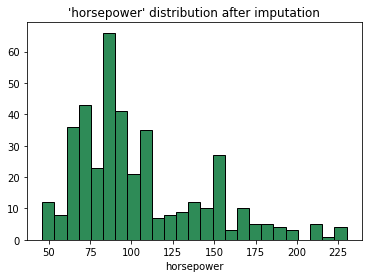

In [6]:
median_hp = df['horsepower'].median()
df['horsepower'] = df['horsepower'].fillna(median_hp)

print(f"Imputed missing 'horsepower' values with median = {median_hp}")
print(f"Remaining missing values in 'horsepower': {df['horsepower'].isna().sum()}")
print(f"Any missing values left in the entire dataset: {df.isna().sum().sum() > 0}")

# Visual sanity check: distribution shape should be essentially unchanged
plt.figure(figsize=(6,4))
plt.hist(df['horsepower'], bins=25, color='seagreen', edgecolor='black')
plt.title("'horsepower' distribution after imputation")
plt.xlabel("horsepower")
plt.show()

## 3. Data Analysis & Visualization

We use three different types of plots to explore relationships between 
features and `mpg`:
1. **Correlation heatmap** — shows linear relationships across all numeric features at a glance.
2. **Scatterplots** — show the relationship of individual features (e.g. `weight`, `horsepower`) to `mpg`.
3. **Boxplot** — shows the distribution of `mpg` across groups (e.g. by `cylinders`), highlighting group differences and outliers.

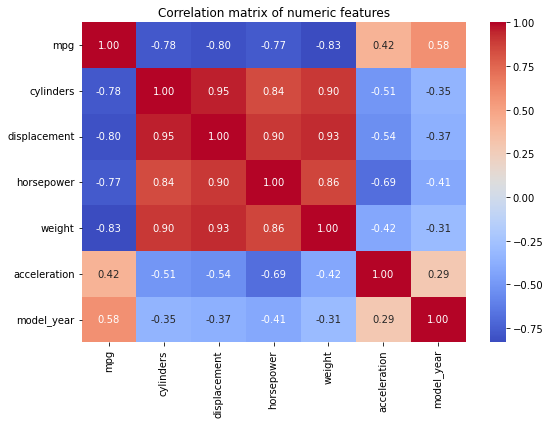

In [7]:
numeric_cols = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation matrix of numeric features")
plt.tight_layout()
plt.show()

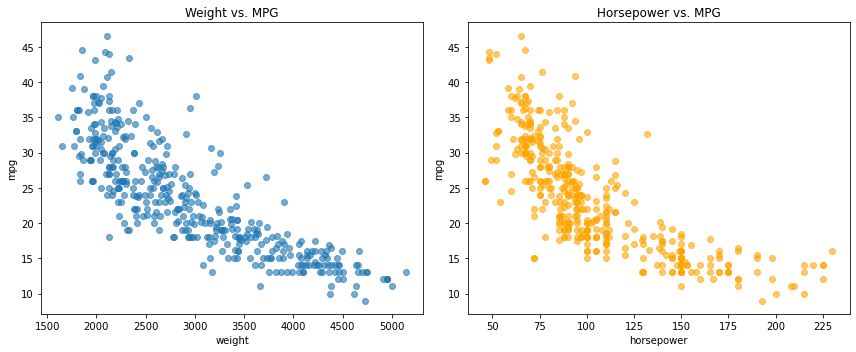

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(df['weight'], df['mpg'], alpha=0.6)
axes[0].set_xlabel("weight"); axes[0].set_ylabel("mpg")
axes[0].set_title("Weight vs. MPG")

axes[1].scatter(df['horsepower'], df['mpg'], alpha=0.6, color='orange')
axes[1].set_xlabel("horsepower"); axes[1].set_ylabel("mpg")
axes[1].set_title("Horsepower vs. MPG")
plt.tight_layout()
plt.show()

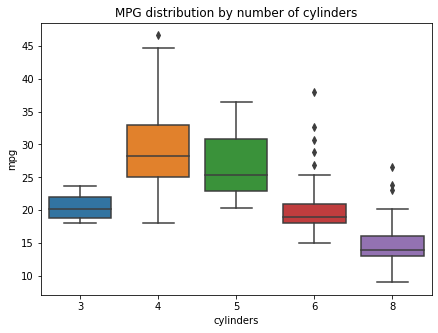

In [9]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='cylinders', y='mpg', data=df)
plt.title("MPG distribution by number of cylinders")
plt.show()

**Feature selection:** The heatmap shows that `weight`, `displacement`, 
`horsepower`, and `cylinders` have the strongest (negative) correlations 
with `mpg`, while `model_year` shows a moderate positive relationship 
(newer cars tend to be more efficient). `acceleration` correlates more 
weakly but still adds information about engine characteristics, so it is 
kept. `origin` is treated as categorical and one-hot encoded, since 
different regions historically had different efficiency standards. The 
`name` column is excluded, as it is too high-dimensional/individual to 
generalize.

We additionally engineer a new feature `power_to_weight` 
(horsepower / weight), which captures engine power relative to vehicle 
mass — a well-known driver of fuel consumption.

In [10]:
df['power_to_weight'] = df['horsepower'] / df['weight']

feature_cols = ['cylinders', 'displacement', 'horsepower', 'weight',
                 'acceleration', 'model_year', 'power_to_weight']

X = df[feature_cols].copy()
X = pd.get_dummies(X.join(df['origin']), columns=['origin'], drop_first=True)
y = df['mpg'].values.astype(np.float32)

print(X.head())
print(f"\nFeature matrix shape: {X.shape}")

   cylinders  displacement  horsepower  weight  acceleration  model_year  \
0          8         307.0       130.0    3504          12.0          70   
1          8         350.0       165.0    3693          11.5          70   
2          8         318.0       150.0    3436          11.0          70   
3          8         304.0       150.0    3433          12.0          70   
4          8         302.0       140.0    3449          10.5          70   

   power_to_weight  origin_2  origin_3  
0         0.037100         0         0  
1         0.044679         0         0  
2         0.043655         0         0  
3         0.043694         0         0  
4         0.040591         0         0  

Feature matrix shape: (398, 9)


## 4. Train/Test Split 

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardization (important for neural networks!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print(f"Training observations: {X_train_scaled.shape[0]}")
print(f"Test observations: {X_test_scaled.shape[0]} ({X_test_scaled.shape[0]/len(X):.0%})")

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train_scaled)
y_train_t = torch.tensor(y_train).view(-1, 1)
X_test_t = torch.tensor(X_test_scaled).to(device)
y_test_t = torch.tensor(y_test).view(-1, 1).to(device)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

Training observations: 318
Test observations: 80 (20%)


## 5. Define & Train a Neural Network

**Modeling choices:** The task requires at least two hidden layers; we use 
**three** hidden layers (32, 16, 8 neurons) to give the network a bit more 
capacity for capturing nonlinear interactions between features, while 
still staying small enough to train in seconds on this dataset. ReLU 
activations introduce nonlinearity, and a single linear output neuron is 
used since `mpg` is a continuous target (regression). MSE is used as the 
loss function, MAE as an additional tracked metric, and Adam as the 
optimizer. No explicit regularization is applied in this baseline model — 
that is addressed separately in Section 7.

In [12]:
class MPGNet(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.0):
        super().__init__()
        layers_list = [nn.Linear(input_dim, 32), nn.ReLU()]
        if dropout_rate > 0:
            layers_list.append(nn.Dropout(dropout_rate))
        layers_list += [nn.Linear(32, 16), nn.ReLU()]
        if dropout_rate > 0:
            layers_list.append(nn.Dropout(dropout_rate))
        layers_list += [nn.Linear(16, 8), nn.ReLU()]
        if dropout_rate > 0:
            layers_list.append(nn.Dropout(dropout_rate))
        layers_list.append(nn.Linear(8, 1))
        self.net = nn.Sequential(*layers_list)

    def forward(self, x):
        return self.net(x)

model_base = MPGNet(input_dim=X_train_scaled.shape[1]).to(device)
print(model_base)

total_params = sum(p.numel() for p in model_base.parameters())
print(f"Total trainable parameters: {total_params}")

MPGNet(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)
Total trainable parameters: 993


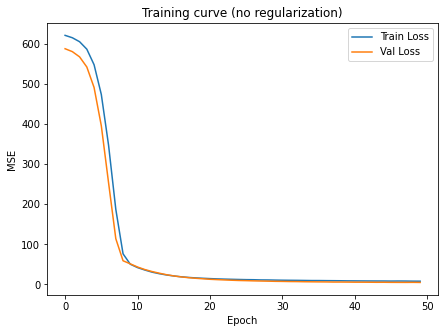

In [13]:
def train_model(model, train_loader, X_test_t, y_test_t, epochs=50, weight_decay=0.0, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * xb.size(0)
        train_losses.append(epoch_loss / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_preds = model(X_test_t)
            val_loss = criterion(val_preds, y_test_t).item()
        val_losses.append(val_loss)

    return train_losses, val_losses

train_losses_base, val_losses_base = train_model(model_base, train_loader, X_test_t, y_test_t)

plt.figure(figsize=(7,5))
plt.plot(train_losses_base, label='Train Loss')
plt.plot(val_losses_base, label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.title('Training curve (no regularization)')
plt.legend()
plt.show()

## 6. Evaluate Predictions on Test Data

Base model (no regularization):
  MAE:  1.754
  RMSE: 2.250
  R²:   0.906


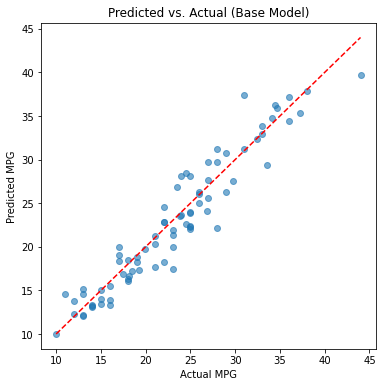

In [14]:
model_base.eval()
with torch.no_grad():
    y_pred_base = model_base(X_test_t).cpu().numpy().flatten()

mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
r2_base = r2_score(y_test, y_pred_base)

print("Base model (no regularization):")
print(f"  MAE:  {mae_base:.3f}")
print(f"  RMSE: {rmse_base:.3f}")
print(f"  R²:   {r2_base:.3f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_base, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Predicted vs. Actual (Base Model)")
plt.show()

## 7. Apply Regularization & Compare 

We apply **dropout (0.3)** combined with **L2 regularization** (via 
`weight_decay` in the Adam optimizer) to reduce overfitting. Dropout 
randomly deactivates neurons during training so the network cannot rely 
too heavily on any single neuron; L2 regularization penalizes large 
weights, encouraging a simpler, more generalizable function.

In [15]:
model_reg = MPGNet(input_dim=X_train_scaled.shape[1], dropout_rate=0.3).to(device)

train_losses_reg, val_losses_reg = train_model(
    model_reg, train_loader, X_test_t, y_test_t, weight_decay=1e-3
)

model_reg.eval()
with torch.no_grad():
    y_pred_reg = model_reg(X_test_t).cpu().numpy().flatten()

mae_reg = mean_absolute_error(y_test, y_pred_reg)
rmse_reg = np.sqrt(mean_squared_error(y_test, y_pred_reg))
r2_reg = r2_score(y_test, y_pred_reg)

print("Regularized model (L2 + Dropout):")
print(f"  MAE:  {mae_reg:.3f}")
print(f"  RMSE: {rmse_reg:.3f}")
print(f"  R²:   {r2_reg:.3f}")

Regularized model (L2 + Dropout):
  MAE:  3.393
  RMSE: 3.965
  R²:   0.708


               Model       MAE      RMSE        R2
0  No Regularization  1.754085  2.249725  0.905866
1       L2 + Dropout  3.393052  3.964548  0.707668


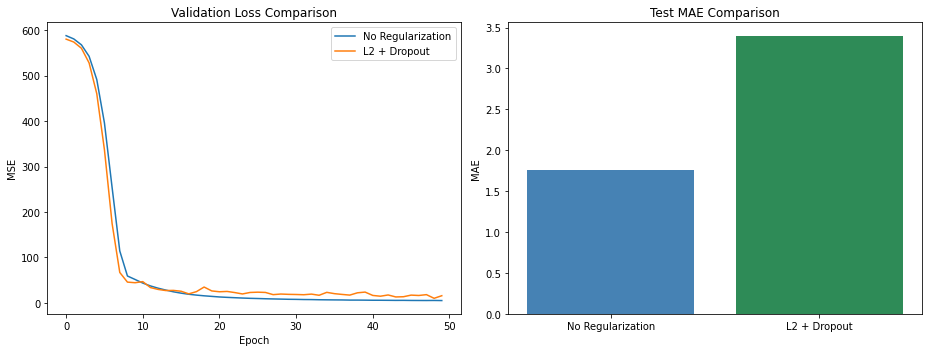

In [16]:
comparison = pd.DataFrame({
    'Model': ['No Regularization', 'L2 + Dropout'],
    'MAE': [mae_base, mae_reg],
    'RMSE': [rmse_base, rmse_reg],
    'R2': [r2_base, r2_reg]
})
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(val_losses_base, label='No Regularization')
axes[0].plot(val_losses_reg, label='L2 + Dropout')
axes[0].set_title('Validation Loss Comparison')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE'); axes[0].legend()

axes[1].bar(comparison['Model'], comparison['MAE'], color=['steelblue', 'seagreen'])
axes[1].set_title('Test MAE Comparison')
axes[1].set_ylabel('MAE')
plt.tight_layout()
plt.show()

**Interpretation:** Contrary to what one might expect, the **regularized 
model performs worse** than the base model on the test set (MAE 3.39 vs. 
1.75, RMSE 3.96 vs. 2.25, R² 0.71 vs. 0.91). The validation loss curves 
explain why: both models converge to a similarly low loss within the first 
~10 epochs, and the base model's validation loss does **not** diverge from 
its training loss afterward — there is no visible overfitting to correct 
in the first place.

Given this, the regularization slightly **underfits** the data instead. 
The network used here is already fairly small (three hidden layers with 
32/16/8 neurons), so combining a relatively strong dropout rate (0.3) with 
L2 weight decay (1e-3) removes too much of the network's already-limited 
capacity — visible in the orange curve settling at a slightly higher and 
noisier loss level than the blue curve. In other words, regularization is 
a lever that should scale with the model's capacity and its actual 
tendency to overfit; if the base model is not overfitting, adding strong 
regularization mainly hurts performance rather than helping it.

This is a useful negative result: it shows that regularization should not 
be applied by default, but chosen based on evidence of overfitting (e.g. a 
growing gap between training and validation loss). A next step could be 
to reduce the dropout rate (e.g. to 0.1–0.2) and/or the weight decay 
strength, or apply regularization only if a larger, higher-capacity 
network starts overfitting.